# Domain: Healthcare

## Context of Dataset

Context
This data set contains 416 liver patient records and 167 non liver patient records collected from North East of Andhra Pradesh, India. The "Target" column is a class label used to divide groups into liver patients (liver disease) or not (no disease). This data set contains 441 male patient records and 142 female patient records.
Any patient whose age exceeded 89 is listed as being of age "90".

Attribute information:
●	Age of the patient
●	Gender of the patient
●	Total Bilirubin
●	Direct Bilirubin
●	Alkaline Phosphotase
●	Alamine Aminotransferase
●	Aspartate Aminotransferase
●	Total Proteins
●	Albumin
●	Albumin and Globulin Ratio
●	Target: field used to split the data into two sets (1: patient with  liver disease and 2: patient with no liver disease)


In [3]:
# Importing required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler,OneHotEncoder, OrdinalEncoder,LabelEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import pickle

In [4]:
# Below shows the path/ location of the dataset

path = '/Users/anmolgupta/Desktop/Datamites Internship/Liver Patient Prediction (PRCP-1007)/Indian Liver Patient Dataset (ILPD).csv'

In [5]:
original_data = pd.read_csv(path)  # saving dataset into original_data variable

In [6]:
df = original_data.copy() #creating df as a copy of the original dataset so original dataset remain unchanged.

In [7]:
df

,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.9,1
0,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
1,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
2,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
3,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
4,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
...,...,...,...,...,...,...,...,...,...,...,...
577,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
578,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
579,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
580,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [8]:
# creating key: value pairs to change the name of columns from old name to new name as mentioned in the context of the dataset.

rename_dict = {
    "65":"Age",
    "Female":"Gender",
    "0.7":"Total_bilirubin",
    "0.1":"Direct_bilirubin",
    "187":"Alkaline_Phosphotase",
    "16":"Alamine_Aminotransferase",
    "18":"Aspartate_Aminotransferase",
    "6.8":"Total_Proteins",
    "3.3":"Albumin",
    "0.9":"Albumin_Globulin_Ratio",
    "1":"Disease"
}

In [9]:
# Renaming the df columns with rename function

df.rename(columns=rename_dict, inplace=True)  

In [10]:
df

,Age,Gender,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
0,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
1,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
2,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
3,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
4,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
...,...,...,...,...,...,...,...,...,...,...,...
577,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
578,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
579,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
580,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


## Initial Basic Checks

In [12]:
df.head()

,Age,Gender,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
0,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
1,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
2,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
3,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
4,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1


In [13]:
df.shape

(582, 11)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         582 non-null    int64  
 1   Gender                      582 non-null    object 
 2   Total_bilirubin             582 non-null    float64
 3   Direct_bilirubin            582 non-null    float64
 4   Alkaline_Phosphotase        582 non-null    int64  
 5   Alamine_Aminotransferase    582 non-null    int64  
 6   Aspartate_Aminotransferase  582 non-null    int64  
 7   Total_Proteins              582 non-null    float64
 8   Albumin                     582 non-null    float64
 9   Albumin_Globulin_Ratio      578 non-null    float64
 10  Disease                     582 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.1+ KB


In [15]:
df.isnull().sum()  #indicates only 4 null values in Albumin_Globulin_Ratio column

Age                           0
Gender                        0
Total_bilirubin               0
Direct_bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_Globulin_Ratio        4
Disease                       0
dtype: int64

In [16]:
df.describe()

,Age,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
count,582.000000,582.000000,582.000000,582.000000,582.000000,582.000000,582.000000,582.000000,578.000000,582.000000
mean,44.711340,3.303265,1.488488,290.754296,80.824742,110.068729,6.482646,3.141581,0.947145,1.286942
std,16.181921,6.213926,2.810324,243.108929,182.757696,289.141876,1.086306,0.796176,0.319863,0.452723
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.250000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.940000,1.000000
75%,57.750000,2.600000,1.300000,298.000000,60.750000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [17]:
df.drop(columns=["Gender"],axis=1).median() #checking median value of all numerical columns

Age                            45.00
Total_bilirubin                 1.00
Direct_bilirubin                0.30
Alkaline_Phosphotase          208.00
Alamine_Aminotransferase       35.00
Aspartate_Aminotransferase     42.00
Total_Proteins                  6.60
Albumin                         3.10
Albumin_Globulin_Ratio          0.94
Disease                         1.00
dtype: float64

In [18]:
df["Disease"].value_counts()

Disease
1    415
2    167
Name: count, dtype: int64

#### Note: 

Based on the dataset, the target variable is identified as the Disease column, which indicates whether a patient has liver disease. 
In this column, a value of 1 represents that the patient has liver disease, while a value of 2 denotes that the patient does not have liver disease.

## Task 1: Data Analysis Report on given data.
## EDA - Explorartory Data Analysis

### 1. Univariant Analysis

In [22]:
# selecting only numerical value colmns in num_col variable

num_col = df.select_dtypes(include=["number"]).columns

In [23]:
num_col

Index(['Age', 'Total_bilirubin', 'Direct_bilirubin', 'Alkaline_Phosphotase',
       'Alamine_Aminotransferase', 'Aspartate_Aminotransferase',
       'Total_Proteins', 'Albumin', 'Albumin_Globulin_Ratio', 'Disease'],
      dtype='object')

#### Plotting Histogram:

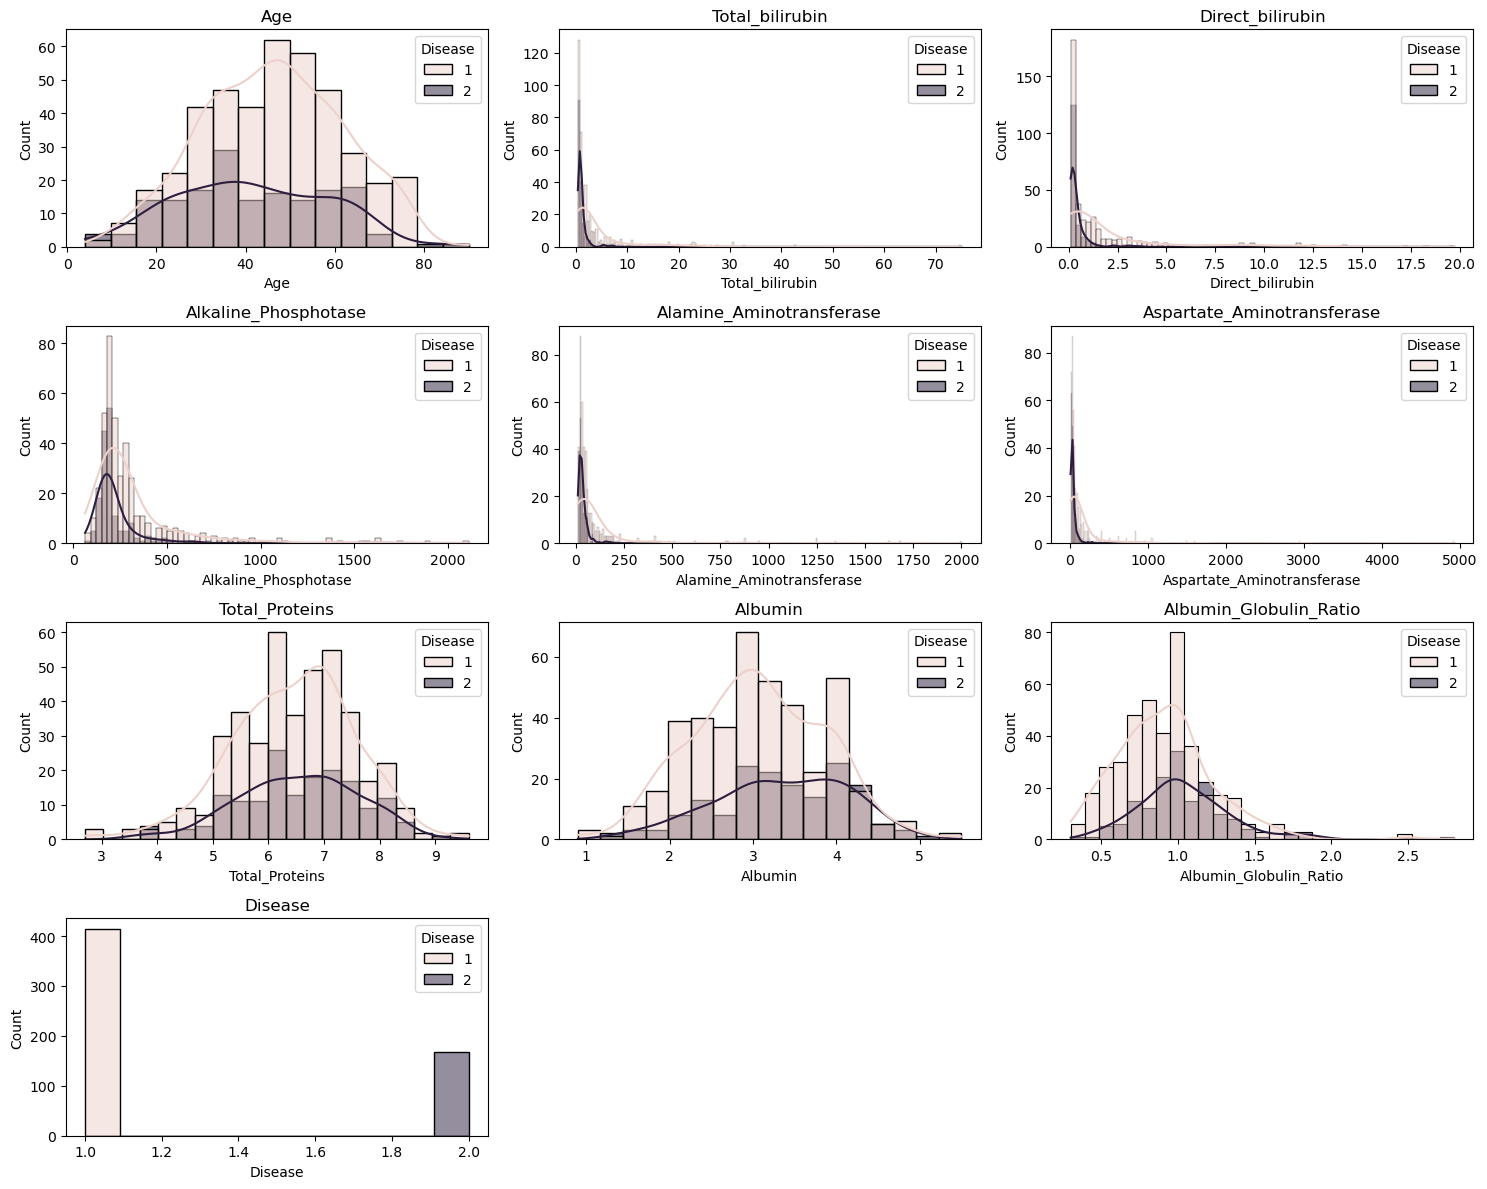

In [25]:
# Plotting histplot on numerical column

plt.figure(figsize=(15,12),facecolor="white")
for i, col in enumerate(num_col):
    plt.subplot(len(num_col)//3 +1,3,i+1)
    sns.histplot(x=df[col],kde=True, hue='Disease', data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Histplot:

•  Histogram plots provide a clear visualization of the distribution of numerical columns.

•  For specific columns — Age, Total_Proteins, Albumin, Albumin_Globulin_Ratio, and Disease — although the values are numerical, they are treated as categorical variables. Accordingly, missing values in these columns are imputed using the mode(), since distinct category counts are present.

•  For the remaining columns, that exhibit continuous distribution curves seems highly right-skewed.

#### Plotting Histplot for Contineous variable column

In [28]:
# Creating skew_col to check the skewness of the columns below 

col = df.loc[:,['Total_bilirubin', 'Direct_bilirubin', 'Alkaline_Phosphotase',
          'Alamine_Aminotransferase', 'Aspartate_Aminotransferase']]

skewed_col = col.columns

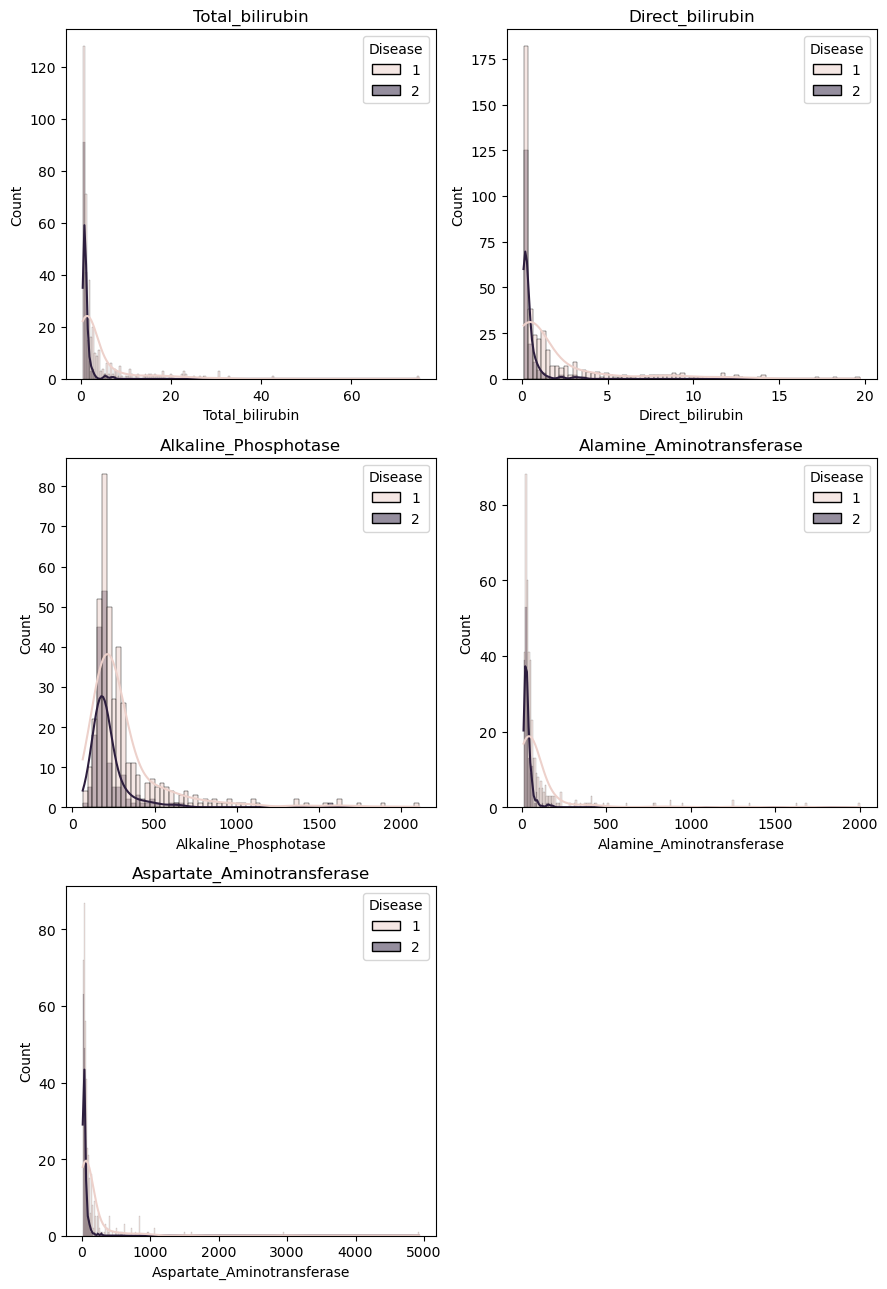

In [29]:
plt.figure(figsize=(9,13),facecolor="white")
for i, col in enumerate(col):
    plt.subplot(len(skewed_col)//2 +1,2,i+1)
    sns.histplot(x=df[col],kde=True, hue='Disease', data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings:

•  All columns exhibit a high degree of right-skewness in their value distributions.

•  Due to this skewness, the median is the most appropriate measure of central tendency for imputation.

•  Accordingly, missing values (NaN) across these columns should be imputed using the median value of each respective column.

#### Plotting Boxplot

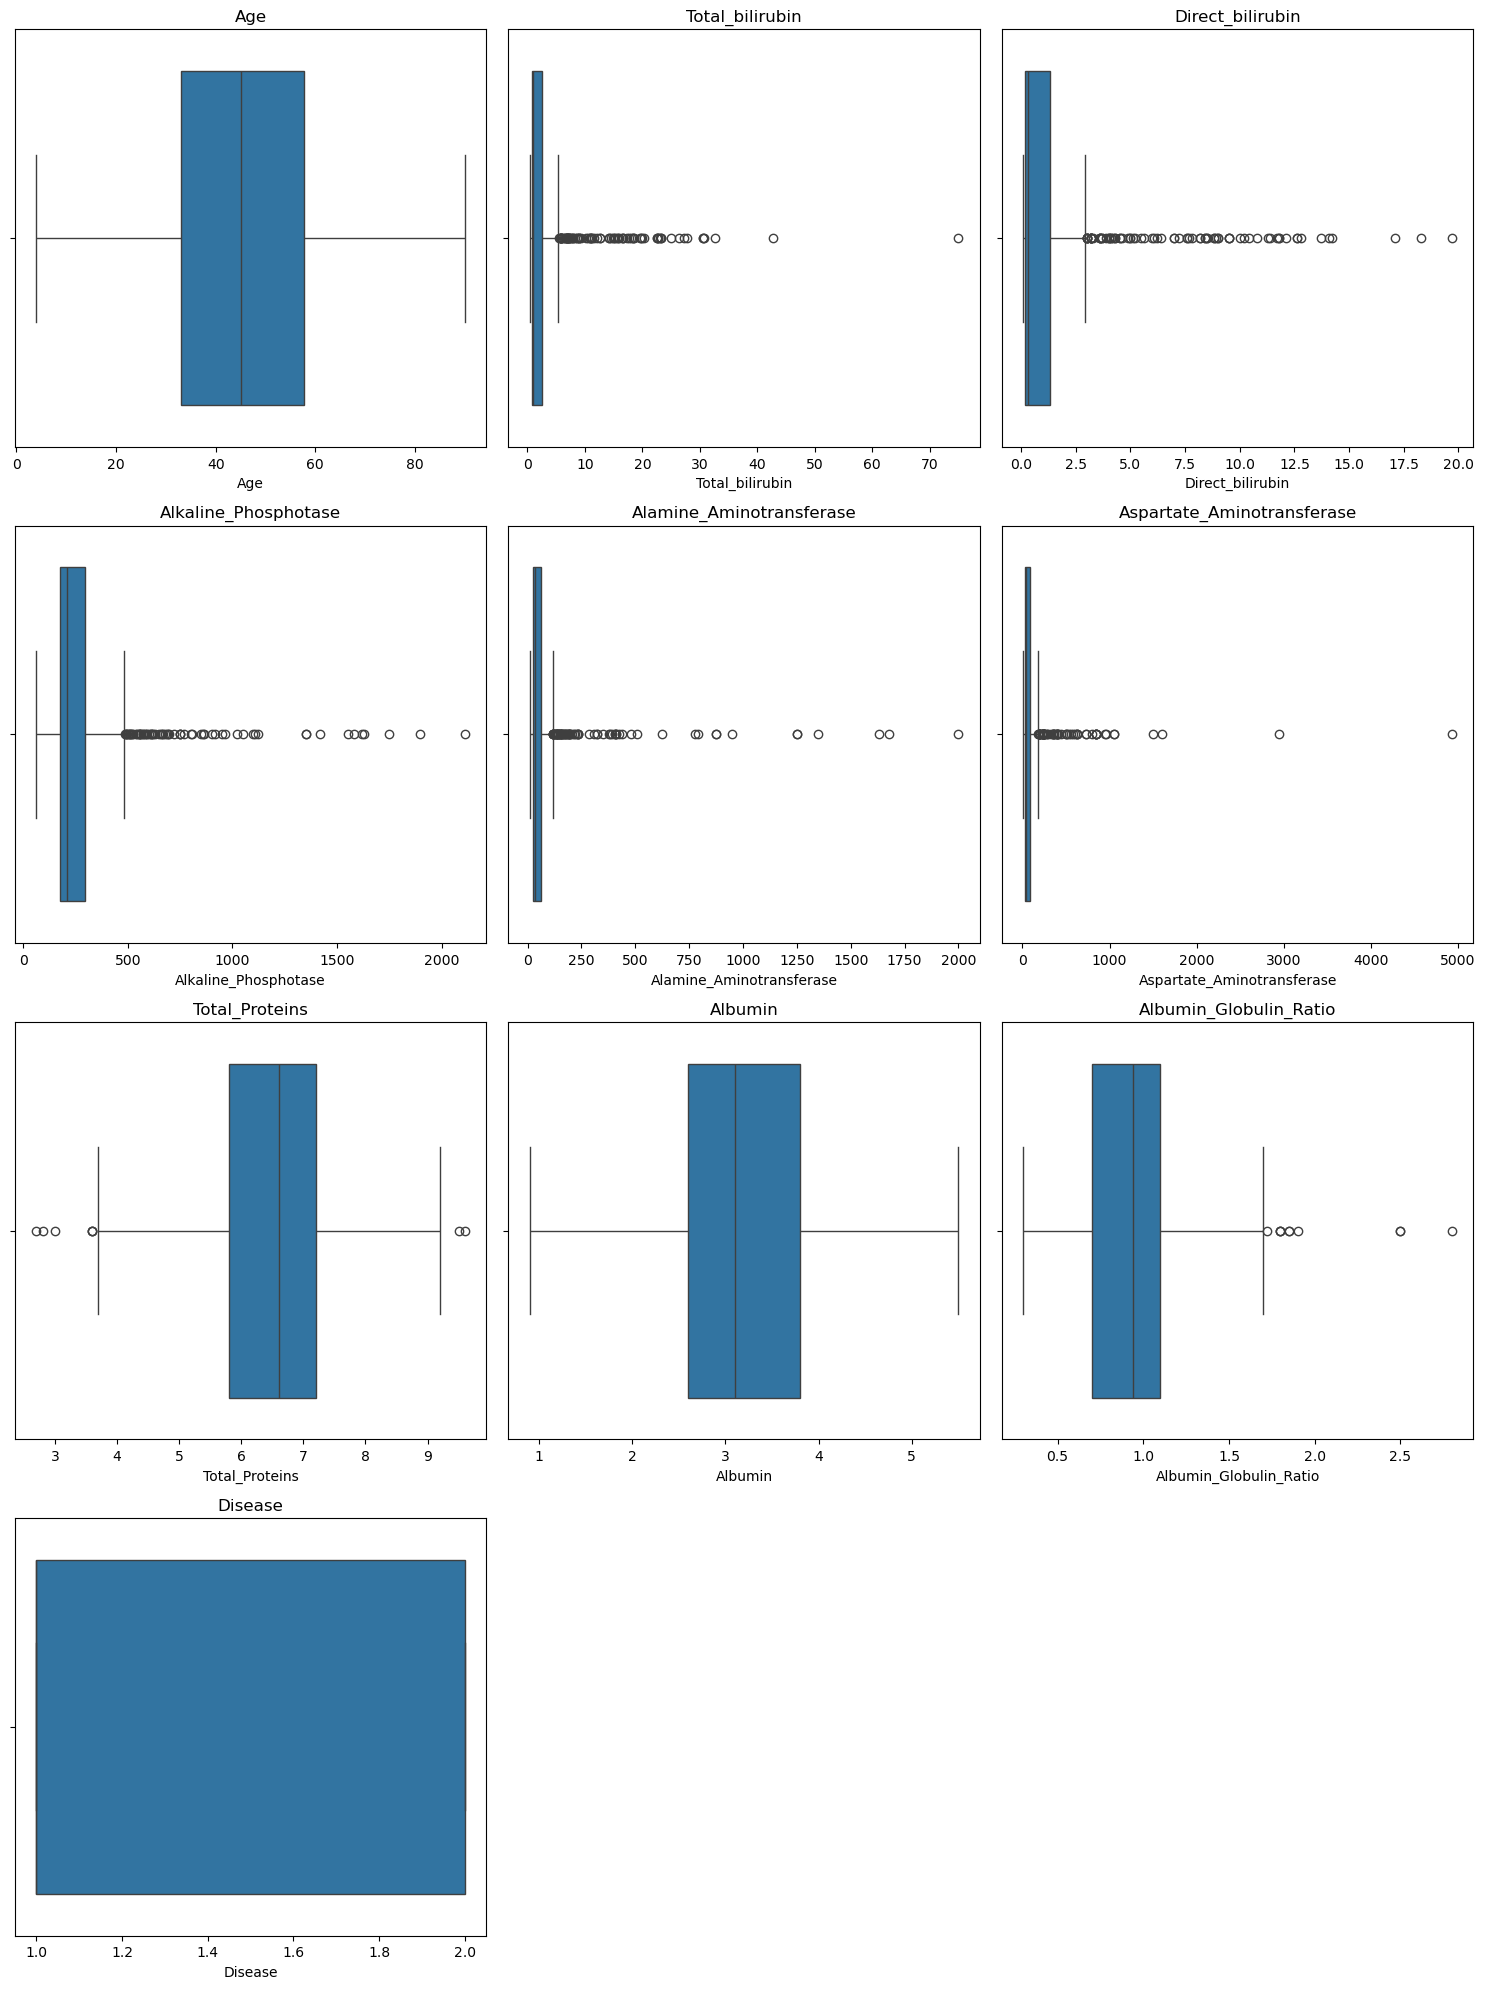

In [32]:
# Ploting Boxplot to check the Outliers

plt.figure(figsize=(15,20),facecolor="white")
for i, col in enumerate(num_col):
    plt.subplot(len(num_col)//3 +1,3,i+1)
    sns.boxplot(x=df[col], orient='h')
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Boxplot:

•  The columns Total_Bilirubin, Direct_Bilirubin, Alkaline_Phosphotase, Alamine_Aminotransferase, and Aspartate_Aminotransferase contain the highest number of outliers, which are observed only beyond the right whisker line, indicating that outliers exist exclusively above the upper bound.

•  The column Total_Proteins has fewer outliers, but they are present on both ends — beyond the left and right whisker lines.

•  The column Albumin_Globulin_Ratio also contains a smaller number of outliers, observed only beyond the right whisker (upper bound).

•  The columns Age and Albumin do not contain any outliers.

### 2. MultiVariate Analysis

#### Ploting Heatmap

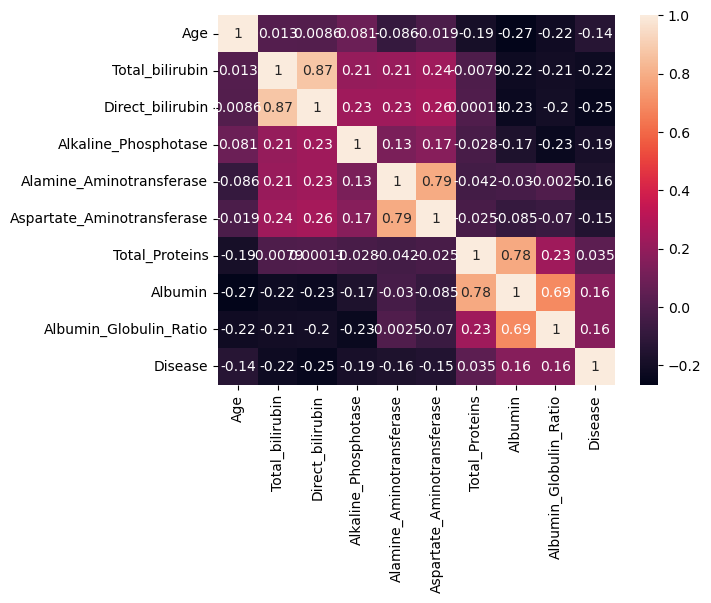

In [36]:
sns.heatmap(df.select_dtypes(include=['int','float']).corr(),annot=True)
plt.show()

#### Findings from Heatmap: check for Multicolinearilty

## Data Preprocessing

#### Imputing Null Values 

In [40]:
df.isnull().sum()     # Checking Nan values

Age                           0
Gender                        0
Total_bilirubin               0
Direct_bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_Globulin_Ratio        4
Disease                       0
dtype: int64

In [41]:
df["Albumin_Globulin_Ratio"].fillna(df["Albumin_Globulin_Ratio"].median(), inplace=True)   # Impute nan values with Median

In [42]:
df.isnull().sum()  # No nan value remaining

Age                           0
Gender                        0
Total_bilirubin               0
Direct_bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_Globulin_Ratio        0
Disease                       0
dtype: int64

#### Dropping Duplcate value

In [44]:
df.duplicated().sum()   # gives count of duplicate rows

13

In [45]:
df[df.duplicated()]     # shows the duplicate rows

,Age,Gender,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
18,40,Female,0.9,0.3,293,232,245,6.8,3.1,0.80,1
25,34,Male,4.1,2.0,289,875,731,5.0,2.7,1.10,1
33,38,Female,2.6,1.2,410,59,57,5.6,3.0,0.80,2
54,42,Male,8.9,4.5,272,31,61,5.8,2.0,0.50,1
61,58,Male,1.0,0.5,158,37,43,7.2,3.6,1.00,1
105,36,Male,5.3,2.3,145,32,92,5.1,2.6,1.00,2
107,36,Male,0.8,0.2,158,29,39,6.0,2.2,0.50,2
137,18,Male,0.8,0.2,282,72,140,5.5,2.5,0.80,1
142,30,Male,1.6,0.4,332,84,139,5.6,2.7,0.90,1
157,72,Male,0.7,0.1,196,20,35,5.8,2.0,0.50,1


In [46]:
# removing Duplicate values

df = df.drop_duplicates()

In [47]:
# Confirmed no duplicate values remain

df.duplicated().sum()  

0

#### Capping Outliers with IQR Method

In [49]:
df.columns

Index(['Age', 'Gender', 'Total_bilirubin', 'Direct_bilirubin',
       'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
       'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin',
       'Albumin_Globulin_Ratio', 'Disease'],
      dtype='object')

In [50]:
df.head()

,Age,Gender,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
0,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
1,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
2,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
3,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
4,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1


In [51]:
# Columns to apply IQR capping
winsor_cols = [
    'Total_bilirubin', 'Direct_bilirubin',
    'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
    'Aspartate_Aminotransferase', 'Total_Proteins',
    'Albumin_Globulin_Ratio'
]

# Apply IQR-based capping
for col in winsor_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    # Winsorize: cap values at bounds
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

In [52]:
df

,Age,Gender,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
0,62,Male,5.3,2.95,481.0,64.0,100.0,7.5,3.2,0.74,1
1,62,Male,5.3,2.95,481.0,60.0,68.0,7.0,3.3,0.89,1
2,58,Male,1.0,0.40,182.0,14.0,20.0,6.8,3.4,1.00,1
3,72,Male,3.9,2.00,195.0,27.0,59.0,7.3,2.4,0.40,1
4,46,Male,1.8,0.70,208.0,19.0,14.0,7.6,4.4,1.30,1
...,...,...,...,...,...,...,...,...,...,...,...
577,60,Male,0.5,0.10,481.0,20.0,34.0,5.9,1.6,0.37,2
578,40,Male,0.6,0.10,98.0,35.0,31.0,6.0,3.2,1.10,1
579,52,Male,0.8,0.20,245.0,48.0,49.0,6.4,3.2,1.00,1
580,31,Male,1.3,0.50,184.0,29.0,32.0,6.8,3.4,1.00,1


In [53]:
def same(x):
    return x
passthrough = FunctionTransformer(same)

#### Creating columns to apply preprocessing funtions to create pipeline

In [55]:
OHE_col = ['Gender']
ss_col = ['Age', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase','Aspartate_Aminotransferase']
pass_through_col = ['Total_bilirubin','Direct_bilirubin','Total_Proteins', 'Albumin', 'Albumin_Globulin_Ratio']

#### Creating preprocessor Pipeline

In [57]:
preprocessor = ColumnTransformer([('OHE',OneHotEncoder(),OHE_col),
                                  ('SS',StandardScaler(),ss_col),
                                  ('Do_Nothing',passthrough,pass_through_col)])
                                

In [58]:
preprocessor

ColumnTransformer(transformers=[('OHE', OneHotEncoder(), ['Gender']),
                                ('SS', StandardScaler(),
                                 ['Age', 'Alkaline_Phosphotase',
                                  'Alamine_Aminotransferase',
                                  'Aspartate_Aminotransferase']),
                                ('Do_Nothing',
                                 FunctionTransformer(func=<function same at 0x162188680>),
                                 ['Total_bilirubin', 'Direct_bilirubin',
                                  'Total_Proteins', 'Albumin',
                                  'Albumin_Globulin_Ratio'])])

In [59]:
# Saving the preprocessor in a file Liver_CT.pkl

with open('Liver_CT','wb') as f:
    pickle.dump(preprocessor,f)

In [60]:
# Saving processed df file

with open('Liver_processed_file','wb') as f:
    pickle.dump(df,f)

### Importing the required module again from python file just to confirm if pickle file is wotking fine and proceed further.

In [62]:
#from processing_data import *

In [63]:
# Loading preprocessor with variable: pre

with open("Liver_CT",'rb') as f:
    pre = pickle.load(f)

In [64]:
# Loading processed dataset file in df

with open("Liver_processed_file",'rb') as f:
    df = pickle.load(f)

In [65]:
pre

ColumnTransformer(transformers=[('OHE', OneHotEncoder(), ['Gender']),
                                ('SS', StandardScaler(),
                                 ['Age', 'Alkaline_Phosphotase',
                                  'Alamine_Aminotransferase',
                                  'Aspartate_Aminotransferase']),
                                ('Do_Nothing',
                                 FunctionTransformer(func=<function same at 0x162188680>),
                                 ['Total_bilirubin', 'Direct_bilirubin',
                                  'Total_Proteins', 'Albumin',
                                  'Albumin_Globulin_Ratio'])])

In [66]:
df

,Age,Gender,Total_bilirubin,Direct_bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_Globulin_Ratio,Disease
0,62,Male,5.3,2.95,481.0,64.0,100.0,7.5,3.2,0.74,1
1,62,Male,5.3,2.95,481.0,60.0,68.0,7.0,3.3,0.89,1
2,58,Male,1.0,0.40,182.0,14.0,20.0,6.8,3.4,1.00,1
3,72,Male,3.9,2.00,195.0,27.0,59.0,7.3,2.4,0.40,1
4,46,Male,1.8,0.70,208.0,19.0,14.0,7.6,4.4,1.30,1
...,...,...,...,...,...,...,...,...,...,...,...
577,60,Male,0.5,0.10,481.0,20.0,34.0,5.9,1.6,0.37,2
578,40,Male,0.6,0.10,98.0,35.0,31.0,6.0,3.2,1.10,1
579,52,Male,0.8,0.20,245.0,48.0,49.0,6.4,3.2,1.00,1
580,31,Male,1.3,0.50,184.0,29.0,32.0,6.8,3.4,1.00,1


#### Splitting the data into x and y

In [68]:
x = df.drop(columns=["Disease"],axis=1)
y = df["Disease"].map({2:0,1:1})

In [69]:
from sklearn.model_selection import train_test_split
x_train_raw,x_test_raw,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [70]:
print(x_train_raw.shape)
print(x_test_raw.shape)
print(y_train.shape)
print(y_test.shape)

(455, 10)
(114, 10)
(455,)
(114,)


In [71]:
# Define categorical and numeric columns
cat_cols = ['Gender']   # OHE needed
num_cols = [col for col in x.columns if col not in cat_cols]

#### Tranforming the data from pipeline

In [73]:
x_train = pre.fit_transform(x_train_raw)
x_test = pre.transform(x_test_raw)

In [74]:
# We can observe that 1 column has increased because of One-Hot Encoding of the Gender Column

print(x_train.shape)
print(x_test.shape)

(455, 11)
(114, 11)


In [75]:
#We can confirm that the classification data is imbalaned, so we need to balance the data.

y_train.value_counts()

Disease
1    319
0    136
Name: count, dtype: int64

#### Using SMOTE() method to solve Imbalancing of Target Classification

In [77]:
from imblearn.over_sampling import SMOTE
from collections import Counter

In [78]:
x_smote,y_smote = SMOTE().fit_resample(x_train,y_train)
print("SMOTE Class Distribution: ", Counter(y_smote))

SMOTE Class Distribution:  Counter({1: 319, 0: 319})


## Task 2: Models Creation:

### Model 1: Logistic Regression:

In [81]:
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression()
LR.fit(x_smote,y_smote)

LogisticRegression()

In [82]:
y_pred = LR.predict(x_test)

##### Evaluation of Model

In [84]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,confusion_matrix,classification_report

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print("Accuracy Score: ",acc,"\nPrecision: ",pr,"\nRecall_Score: ",re,'\nF1_Score: ',f1,'\nConfusion Matrix: \n',cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6140350877192983 
Precision:  0.8387096774193549 
Recall_Score:  0.6046511627906976 
F1_Score:  0.7027027027027027 
Confusion Matrix: 
 [[18 10]
 [34 52]]
              precision    recall  f1-score   support

           0       0.35      0.64      0.45        28
           1       0.84      0.60      0.70        86

    accuracy                           0.61       114
   macro avg       0.59      0.62      0.58       114
weighted avg       0.72      0.61      0.64       114



In [85]:
results = pd.DataFrame(index=['Accuracy','Recall','F1_Score'])

In [86]:
results['Logistic_Reg'] = [acc,re,f1]
results

,Logistic_Reg
Accuracy,0.614035
Recall,0.604651
F1_Score,0.702703


### Model 2: Support Vector Classifier

In [88]:
from sklearn.svm import SVC
svclassifier = SVC(random_state=42)
svclassifier.fit(x_smote,y_smote)

SVC(random_state=42)

In [89]:
import sklearn
sklearn.set_config(print_changed_only=False)

In [90]:
svclassifier

SVC(C=1.0, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=3, gamma='scale', kernel='rbf',
    max_iter=-1, probability=False, random_state=42, shrinking=True, tol=0.001,
    verbose=False)

In [91]:
y_pred = svclassifier.predict(x_test)

In [92]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,confusion_matrix,classification_report

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print("Accuracy Score: ",acc,"\nPrecision: ",pr,"\nRecall_Score: ",re,'\nF1_Score: ',f1,'\nConfusion Matrix: \n',cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.5789473684210527 
Precision:  0.8653846153846154 
Recall_Score:  0.5232558139534884 
F1_Score:  0.6521739130434783 
Confusion Matrix: 
 [[21  7]
 [41 45]]
              precision    recall  f1-score   support

           0       0.34      0.75      0.47        28
           1       0.87      0.52      0.65        86

    accuracy                           0.58       114
   macro avg       0.60      0.64      0.56       114
weighted avg       0.74      0.58      0.61       114



In [93]:
results['SVC'] = [acc,re,f1]
results

,Logistic_Reg,SVC
Accuracy,0.614035,0.578947
Recall,0.604651,0.523256
F1_Score,0.702703,0.652174


In [94]:
# Crosss-Validation technique to take different loops so whole dataset would get used to train and test data

from sklearn.model_selection import cross_val_score
scores = cross_val_score(SVC(),x_train,y_train,cv=10,scoring='f1',n_jobs=-1)
print(scores)
print("cross_validation_score: ",scores.mean())
print("standard_deviation: ",scores.std())

[0.82051282 0.82051282 0.82051282 0.82051282 0.82051282 0.82666667
 0.83116883 0.84210526 0.83116883 0.81578947]
cross_validation_score:  0.8249463168410538
standard_deviation:  0.007462946042996851


In [95]:
# std value < 0.05 considered more stable model.

#### Hyperparameter Tuning for SVC

In [97]:
from sklearn.model_selection import GridSearchCV
param_grid = {'C':[0.1,0.5,1,10,100],'gamma':[1,0.1,0.5,3],'kernel':['sigmoid','rbf']}
grid = GridSearchCV(SVC(random_state=42),param_grid,scoring='f1',cv=5,n_jobs=-1)
grid.fit(x_train,y_train)

GridSearchCV(cv=5, error_score=nan,
             estimator=SVC(C=1.0, break_ties=False, cache_size=200,
                           class_weight=None, coef0=0.0,
                           decision_function_shape='ovr', degree=3,
                           gamma='scale', kernel='rbf', max_iter=-1,
                           probability=False, random_state=42, shrinking=True,
                           tol=0.001, verbose=False),
             n_jobs=-1,
             param_grid={'C': [0.1, 0.5, 1, 10, 100], 'gamma': [1, 0.1, 0.5, 3],
                         'kernel': ['sigmoid', 'rbf']},
             pre_dispatch='2*n_jobs', refit=True, return_train_score=False,
             scoring='f1', verbose=0)

In [98]:
grid.best_params_

{'C': 0.5, 'gamma': 1, 'kernel': 'rbf'}

In [99]:
model = SVC(C=0.5, gamma=1,kernel='rbf', random_state=42)
model.fit(x_smote,y_smote)
y_pred = model.predict(x_test)

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print("Accuracy Score: ",acc,"\nPrecision: ",pr,"\nRecall_Score: ",re,'\nF1_Score: ',f1,'\nConfusion Matrix: \n',cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6929824561403509 
Precision:  0.8072289156626506 
Recall_Score:  0.7790697674418605 
F1_Score:  0.7928994082840237 
Confusion Matrix: 
 [[12 16]
 [19 67]]
              precision    recall  f1-score   support

           0       0.39      0.43      0.41        28
           1       0.81      0.78      0.79        86

    accuracy                           0.69       114
   macro avg       0.60      0.60      0.60       114
weighted avg       0.70      0.69      0.70       114



In [100]:
results['SVC/HPT'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT
Accuracy,0.614035,0.578947,0.692982
Recall,0.604651,0.523256,0.779070
F1_Score,0.702703,0.652174,0.792899


### Model 3: Decision Tree

In [102]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(x_smote,y_smote)

DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=None, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, random_state=None, splitter='best')

In [103]:
y_pred = dt.predict(x_test)

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print("Accuracy Score: ",acc,"\nPrecision: ",pr,"\nRecall_Score: ",re,'\nF1_Score: ',f1,'\nConfusion Matrix: \n',cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6754385964912281 
Precision:  0.7951807228915663 
Recall_Score:  0.7674418604651163 
F1_Score:  0.7810650887573964 
Confusion Matrix: 
 [[11 17]
 [20 66]]
              precision    recall  f1-score   support

           0       0.35      0.39      0.37        28
           1       0.80      0.77      0.78        86

    accuracy                           0.68       114
   macro avg       0.58      0.58      0.58       114
weighted avg       0.69      0.68      0.68       114



In [104]:
results['Decision Tree'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree
Accuracy,0.614035,0.578947,0.692982,0.675439
Recall,0.604651,0.523256,0.779070,0.767442
F1_Score,0.702703,0.652174,0.792899,0.781065


In [105]:
# Using GridSearchCV to get best parameters for HPT

params = {
    "criterion":("gini", "entropy"), #Split criterion
    "splitter":("best", "random"),  #searches the features for a split
    "max_depth":(list(range(1,20,2))),  #depth of tree range from 1 to 19
    "min_samples_split":[2,5,7,10,12,15],    #the minimum number of samples required to split internal node
    "min_samples_leaf":list(range(1, 20)), #minimum number of samples required to be at a leaf node,we are passing list which is range from 1 to 19
}


tree_clf = DecisionTreeClassifier()              # object creation for decision tree with random state 3
tree_cv = GridSearchCV(tree_clf, params, scoring="f1", n_jobs=-1, verbose=5, cv=5)

In [106]:
tree_cv.fit(x_train,y_train)    # training data on gridsearch cv
best_params = tree_cv.best_params_    # it will give you best parameters
print(f"Best paramters: {best_params})")   # printing  best parameters

Fitting 5 folds for each of 4560 candidates, totalling 22800 fits
[CV 3/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2, splitter=best;, score=0.826 total time=   0.0s
[CV 4/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2, splitter=random;, score=0.826 total time=   0.0s
[CV 1/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5, splitter=best;, score=0.826 total time=   0.0s
[CV 3/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5, splitter=best;, score=0.826 total time=   0.0s
[CV 2/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5, splitter=random;, score=0.826 total time=   0.0s
[CV 3/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5, splitter=random;, score=0.826 total time=   0.0s
[CV 4/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=7, splitter=random;, score=0.826 total time=   0.0s
[CV 5/5] END cri

In [107]:
print(f"Best paramters: {best_params})")

Best paramters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 9, 'min_samples_split': 12, 'splitter': 'random'})


In [265]:
# HPT/ passing best parameters to decision tree

dt_optimal=DecisionTreeClassifier(criterion='gini',max_depth=3,min_samples_leaf=9,min_samples_split=12,splitter='random')
dt_optimal.fit(x_smote,y_smote)

y_pred=dt_optimal.predict(x_test)

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.5526315789473685 
Precision: 0.926829268292683 
Recall Score: 0.4418604651162791 
F1 Score 0.5984251968503937 
Confusion Matrix: 
 [[25  3]
 [48 38]]
              precision    recall  f1-score   support

           0       0.34      0.89      0.50        28
           1       0.93      0.44      0.60        86

    accuracy                           0.55       114
   macro avg       0.63      0.67      0.55       114
weighted avg       0.78      0.55      0.57       114



In [267]:
results['DT/HPT'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest,RF/HPT,Grad_Boost,GB/HPT,XGBoost,XGB/HPT
Accuracy,0.614035,0.578947,0.692982,0.675439,0.552632,0.692982,0.701754,0.666667,0.649123,0.675439,0.614035
Recall,0.604651,0.523256,0.779070,0.767442,0.441860,0.767442,0.744186,0.779070,0.686047,0.813953,0.686047
F1_Score,0.702703,0.652174,0.792899,0.781065,0.598425,0.790419,0.790123,0.779070,0.746835,0.790960,0.728395


### Model 4: Random Forest Classifier

In [111]:
from sklearn.ensemble import RandomForestClassifier   # importing randomforest

rf_clf = RandomForestClassifier() # Assigning RandomForest CLassifier into variable
rf_clf.fit(x_smote,y_smote)   # training the data
y_pred=rf_clf.predict(x_test) 

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6929824561403509 
Precision: 0.8148148148148148 
Recall Score: 0.7674418604651163 
F1 Score 0.7904191616766467 
Confusion Matrix: 
 [[13 15]
 [20 66]]
              precision    recall  f1-score   support

           0       0.39      0.46      0.43        28
           1       0.81      0.77      0.79        86

    accuracy                           0.69       114
   macro avg       0.60      0.62      0.61       114
weighted avg       0.71      0.69      0.70       114



In [112]:
results['RandomForest'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest
Accuracy,0.614035,0.578947,0.692982,0.675439,0.614035,0.692982
Recall,0.604651,0.523256,0.779070,0.767442,0.662791,0.767442
F1_Score,0.702703,0.652174,0.792899,0.781065,0.721519,0.790419


In [113]:
rf_clf

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=None,
                       oob_score=False, random_state=None, verbose=0,
                       warm_start=False)

In [114]:
from sklearn.model_selection import RandomizedSearchCV
n_estimators = [int(x) for x in np.linspace(start=200, stop=2000, num=5)]      # List Comprehension-using for loop in list
max_features = ['auto', 'sqrt','log2']        # maximum number of features allowed to try in individual tree
max_depth = [int(x) for x in np.linspace(10, 110, num=5)]            # List Comprehension-using for loop in list
min_samples_split = [5,7,10,13]          # minimum number of samples required to split an internal node
min_samples_leaf = [2, 4]              # minimum number of samples required to be at a leaf node.

#dictionary for hyperparameters
random_grid = {'n_estimators': n_estimators, 'max_features': max_features,
               'max_depth': max_depth, 'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

rf_clf1 = RandomForestClassifier(random_state=42)   # Loading the model

rf_cv = RandomizedSearchCV(estimator=rf_clf1, scoring='f1',param_distributions= random_grid, cv=3,
                               verbose=2, n_jobs=-1)

In [115]:
rf_cv.fit(x_train, y_train)
rf_best_params = rf_cv.best_params_ 
print(f"Best paramters: {rf_best_params})") 

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best paramters: {'n_estimators': 200, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 60})


In [269]:
# passing best parameter to randomforest
rf_clf2 = RandomForestClassifier(n_estimators=200,min_samples_leaf=2,min_samples_split=13,max_features="sqrt",max_depth=60)
rf_clf2.fit(x_smote,y_smote)

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=60, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=2,
                       min_samples_split=13, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=200, n_jobs=None,
                       oob_score=False, random_state=None, verbose=0,
                       warm_start=False)

In [271]:
y_pred=rf_clf2.predict(x_test)

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.7017543859649122 
Precision: 0.825 
Recall Score: 0.7674418604651163 
F1 Score 0.7951807228915663 
Confusion Matrix: 
 [[14 14]
 [20 66]]
              precision    recall  f1-score   support

           0       0.41      0.50      0.45        28
           1       0.82      0.77      0.80        86

    accuracy                           0.70       114
   macro avg       0.62      0.63      0.62       114
weighted avg       0.72      0.70      0.71       114



In [273]:
results['RF/HPT'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest,RF/HPT,Grad_Boost,GB/HPT,XGBoost,XGB/HPT
Accuracy,0.614035,0.578947,0.692982,0.675439,0.552632,0.692982,0.701754,0.666667,0.649123,0.675439,0.614035
Recall,0.604651,0.523256,0.779070,0.767442,0.441860,0.767442,0.767442,0.779070,0.686047,0.813953,0.686047
F1_Score,0.702703,0.652174,0.792899,0.781065,0.598425,0.790419,0.795181,0.779070,0.746835,0.790960,0.728395


### Model 5: Gradient Boost and XGB

In [120]:
from sklearn.ensemble import GradientBoostingClassifier  # Importing GradientBoostingClassifier
gbm=GradientBoostingClassifier() ## object creation
gbm.fit(x_smote,y_smote) ## fitting the data

y_pred=gbm.predict(x_test)

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6666666666666666 
Precision: 0.7790697674418605 
Recall Score: 0.7790697674418605 
F1 Score 0.7790697674418605 
Confusion Matrix: 
 [[ 9 19]
 [19 67]]
              precision    recall  f1-score   support

           0       0.32      0.32      0.32        28
           1       0.78      0.78      0.78        86

    accuracy                           0.67       114
   macro avg       0.55      0.55      0.55       114
weighted avg       0.67      0.67      0.67       114



In [121]:
results['Grad_Boost'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest,RF/HPT,Grad_Boost
Accuracy,0.614035,0.578947,0.692982,0.675439,0.614035,0.692982,0.701754,0.666667
Recall,0.604651,0.523256,0.779070,0.767442,0.662791,0.767442,0.744186,0.779070
F1_Score,0.702703,0.652174,0.792899,0.781065,0.721519,0.790419,0.790123,0.779070


In [122]:
gbm

GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                           learning_rate=0.1, loss='log_loss', max_depth=3,
                           max_features=None, max_leaf_nodes=None,
                           min_impurity_decrease=0.0, min_samples_leaf=1,
                           min_samples_split=2, min_weight_fraction_leaf=0.0,
                           n_estimators=100, n_iter_no_change=None,
                           random_state=None, subsample=1.0, tol=0.0001,
                           validation_fraction=0.1, verbose=0,
                           warm_start=False)

In [123]:
## Hyperparameter tuning for GradientBoost
# Importing RandomizedSearchCV from sklearn
from sklearn.model_selection import RandomizedSearchCV

# Define Parameters grid for learning_rate, max_depth, n_estimators
param_grid = {
    'learning_rate': [0.01, 0.03, 0.06, 0.1, 0.4, 0.5, 0.6, 0.7],
    'max_depth': [5, 6, 7, 8, 9, 10],
    'n_estimators': [50, 65, 80, 100]
}
GB=GradientBoostingClassifier()  # Assigning GradientBoostingClassifier model into variables

rcv= RandomizedSearchCV(estimator=GB, scoring='f1',refit = True,param_distributions=param_grid, cv=5,
                               verbose=2, n_jobs=-1)
rcv.fit(x_train,y_train)
rcv.best_params_

Fitting 5 folds for each of 10 candidates, totalling 50 fits

[CV 3/5] END criterion=entropy, max_depth=19, min_samples_leaf=4, min_samples_split=15, splitter=random;, score=0.803 total time=   0.0s
[CV 4/5] END criterion=entropy, max_depth=19, min_samples_leaf=4, min_samples_split=15, splitter=random;, score=0.782 total time=   0.0s
[CV 5/5] END criterion=entropy, max_depth=19, min_samples_leaf=4, min_samples_split=15, splitter=random;, score=0.800 total time=   0.0s
[CV 1/5] END criterion=entropy, max_depth=19, min_samples_leaf=5, min_samples_split=2, splitter=best;, score=0.756 total time=   0.0s
[CV 2/5] END criterion=entropy, max_depth=19, min_samples_leaf=5, min_samples_split=2, splitter=best;, score=0.764 total time=   0.0s
[CV 3/5] END criterion=entropy, max_depth=19, min_samples_leaf=5, min_samples_split=2, splitter=best;, score=0.746 total time=   0.0s
[CV 4/5] END criterion=entropy, max_depth=19, min_samples_leaf=5, min_samples_split=2, splitter=best;, score=0.776 total time

{'n_estimators': 50, 'max_depth': 7, 'learning_rate': 0.01}

In [275]:
GB2=GradientBoostingClassifier(n_estimators=50, max_depth=7, learning_rate=0.01)
GB2.fit(x_smote,y_smote)

y_pred=GB2.predict(x_test)

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.631578947368421 
Precision: 0.7894736842105263 
Recall Score: 0.6976744186046512 
F1 Score 0.7407407407407407 
Confusion Matrix: 
 [[12 16]
 [26 60]]
              precision    recall  f1-score   support

           0       0.32      0.43      0.36        28
           1       0.79      0.70      0.74        86

    accuracy                           0.63       114
   macro avg       0.55      0.56      0.55       114
weighted avg       0.67      0.63      0.65       114



In [277]:
results['GB/HPT'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest,RF/HPT,Grad_Boost,GB/HPT,XGBoost,XGB/HPT
Accuracy,0.614035,0.578947,0.692982,0.675439,0.552632,0.692982,0.701754,0.666667,0.631579,0.675439,0.614035
Recall,0.604651,0.523256,0.779070,0.767442,0.441860,0.767442,0.767442,0.779070,0.697674,0.813953,0.686047
F1_Score,0.702703,0.652174,0.792899,0.781065,0.598425,0.790419,0.795181,0.779070,0.740741,0.790960,0.728395


### XGBoosting

In [127]:
from xgboost import XGBClassifier#importing the model library
xgb_r=XGBClassifier() ## object creation
xgb_r.fit(x_train,y_train)# fitting the data
y_pred=xgb_r.predict(x_test)#predicting the price

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6754385964912281 
Precision: 0.7692307692307693 
Recall Score: 0.813953488372093 
F1 Score 0.7909604519774012 
Confusion Matrix: 
 [[ 7 21]
 [16 70]]
              precision    recall  f1-score   support

           0       0.30      0.25      0.27        28
           1       0.77      0.81      0.79        86

    accuracy                           0.68       114
   macro avg       0.54      0.53      0.53       114
weighted avg       0.66      0.68      0.66       114



In [128]:
results['XGBoost'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest,RF/HPT,Grad_Boost,GB/HPT,XGBoost
Accuracy,0.614035,0.578947,0.692982,0.675439,0.614035,0.692982,0.701754,0.666667,0.649123,0.675439
Recall,0.604651,0.523256,0.779070,0.767442,0.662791,0.767442,0.744186,0.779070,0.686047,0.813953
F1_Score,0.702703,0.652174,0.792899,0.781065,0.721519,0.790419,0.790123,0.779070,0.746835,0.790960


In [129]:
xgb_r

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [130]:
#Hyperparameter tuning
param_grid = {'gamma': [0,0.1,0.2,0.4],
              'learning_rate': [0.01, 0.03, 0.06, 0.1],
              'max_depth': [5,6,7,8,9],
              'n_estimators': [50,65,80],
              'reg_alpha': [0,0.1,0.2,0.4],
              'reg_lambda': [0,0.1,0.2]}

XGB=XGBClassifier(random_state=42,verbosity=0,silent=0)  # Assigning XGBClassifier model into variables
rcv= GridSearchCV(estimator=XGB, scoring='f1',refit=True,param_grid=param_grid,  cv=3,
                               verbose=1, n_jobs=-1)
rcv.fit(x_train,y_train)
rcv.best_params_

Fitting 3 folds for each of 2880 candidates, totalling 8640 fits


{'gamma': 0,
 'learning_rate': 0.01,
 'max_depth': 9,
 'n_estimators': 50,
 'reg_alpha': 0.4,
 'reg_lambda': 0.1}

In [131]:
XGB2=XGBClassifier(reg_lambda= 0.1, reg_alpha= 0.4, n_estimators=50, max_depth=9, learning_rate=0.01, gamma=0)
XGB2.fit(x_smote,y_smote)
y_pred=XGB2.predict(x_test)#testing

acc = accuracy_score(y_test,y_pred)
pr = precision_score(y_test,y_pred)
re = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
print('Accuracy Score: ',acc,'\nPrecision:', pr,'\nRecall Score:', re,'\nF1 Score', f1, '\nConfusion Matrix: \n', cm)
print(classification_report(y_test,y_pred))

Accuracy Score:  0.6140350877192983 
Precision: 0.7763157894736842 
Recall Score: 0.686046511627907 
F1 Score 0.7283950617283951 
Confusion Matrix: 
 [[11 17]
 [27 59]]
              precision    recall  f1-score   support

           0       0.29      0.39      0.33        28
           1       0.78      0.69      0.73        86

    accuracy                           0.61       114
   macro avg       0.53      0.54      0.53       114
weighted avg       0.66      0.61      0.63       114



In [279]:
results['XGB/HPT'] = [acc,re,f1]
results

,Logistic_Reg,SVC,SVC/HPT,Decision Tree,DT/HPT,RandomForest,RF/HPT,Grad_Boost,GB/HPT,XGBoost,XGB/HPT
Accuracy,0.614035,0.578947,0.692982,0.675439,0.552632,0.692982,0.701754,0.666667,0.631579,0.675439,0.631579
Recall,0.604651,0.523256,0.779070,0.767442,0.441860,0.767442,0.767442,0.779070,0.697674,0.813953,0.697674
F1_Score,0.702703,0.652174,0.792899,0.781065,0.598425,0.790419,0.795181,0.779070,0.740741,0.790960,0.740741


## Task 3: Model Design Analysis

#### 1.Business and Data Context:
•  The dataset showed class imbalance, meaning one class had far fewer samples than the other.

•  The problem domain required high recall (catching as many true positives as possible) and balanced F1-score, since missing positive cases would be costly.

•  Accuracy alone was not sufficient, as it could be misleading in imbalanced datasets.

#### 2.Basis for Model Selection:
•  Metric Priority:
  ⁠◦  Recall was prioritized to minimize false negatives.
  ⁠◦  F1-score was used to balance precision and recall.
  ⁠◦  Accuracy was considered secondary, as it can be inflated by majority class predictions.
  
•  Algorithm Choice:
  ⁠◦  Ensemble methods (Random Forest, Gradient Boosting, XGBoost) were included because they handle complex relationships and imbalanced data better than single models.
  ⁠◦  Simpler models (Logistic Regression, SVC, Decision Tree) were tested as baselines to compare improvements.
  
•  Hyperparameter Tuning:
  ⁠◦  GridSearchCV was applied to optimize parameters like tree depth, learning rate, and regularization.
  ⁠◦  However, tuned versions did not always outperform defaults, showing that over‑optimization can reduce generalization.

#### 3. Techniques applied:
•  SMOTE Oversampling: Balanced the training set to improve recall and F1.

•  Scaling (StandardScaler): Applied for SVC and Logistic Regression to normalize feature ranges.

•  Cross-Validation: Ensured robust evaluation and avoided overfitting to a single split.

## Task 4: Model Comparison Report:

#### Objective:

To evaluate multiple machine‑learning models on the given dataset and identify the most suitable candidate for production deployment based on Accuracy, Recall, and F1‑Score.

#### Models Evaluated:

Baseline - Logistic Regression, SVC, Decision Tree, Random Forest, Gradient Boosting, XGBoost

After Hyperparameter Tuning(HPT) - SVC/HPT, DT/HPT, RF/HPT, GB/HPT, XGB/HPT

#### Best Performance:
Accuracy: Random Forest - 0.70

Recall: XGBoost - 0.81

F1‑Score: XGBoost - 0.79

#### Observation:

•  XGBoost and Gradient Boosting achieved the highest recall and F1‑scores, indicating strong sensitivity and balance.

•  Hyperparameter tuning did not consistently improve results; some tuned models showed reduced recall or accuracy.


#### Conclusion:

After comprehensive evaluation, XGBoost demonstrates the best overall performance and reliability. Its superior recall and balanced F1‑score make it the best choice for production deployment, ensuring reliable detection of positive cases while maintaining generalization on unseen data.

## Task 5: Challenges Encountered Report:

•  Class Imbalance:  
The dataset had significantly more samples in one class compared to the other, which risked biasing models toward majority predictions.

•  Feature Scaling:  
Algorithms like SVC and Logistic Regression are sensitive to feature magnitudes, requiring normalization.

•  Model Overfitting:  
Complex models (Decision Trees, Random Forests, XGBoost) showed a tendency to memorize training data without generalizing well.

•  Hyperparameter Sensitivity:  
Performance varied widely depending on parameters like tree depth, learning rate, and regularization strength.

#### Techniques Used:

•  SMOTE (Synthetic Minority Oversampling Technique):  
Applied to the training set to balance classes. This improved recall and F1-score by ensuring the minority class was adequately represented.

•  StandardScaler:  
Used for SVC and Logistic Regression to normalize feature ranges, preventing bias toward features with larger scales.

•  Cross-Validation:  
Employed k-fold CV to evaluate models consistently and avoid overfitting to a single train-test split.

•  GridSearchCV:  
Used for hyperparameter tuning across SVC, Decision Tree, Random Forest, Gradient Boosting, and XGBoost. This ensured optimal parameter selection based on F1-score.

•  Ensemble Methods (RF, GB, XGB):  
Leveraged ensemble learning to reduce variance and improve predictive power compared to single models.

#### Prediction of a new datapoint set to check if patient has Liver Disease or not.

In [143]:
# Numeric + encoded categorical names
num_features = num_cols
cat_features = pre.named_transformers_['OHE'].get_feature_names_out(cat_cols)
all_features = list(num_features) + list(cat_features)

# Convert back to DataFrame
x_train_df = pd.DataFrame(x_train, columns=all_features)

In [144]:
from xgboost import XGBClassifier
import pandas as pd

# Example: one patient’s data (must match training features)
new_patient = {
    'Age': 45,
    'Gender': 1,   
    'Total_Bilirubin': 1.2,
    'Direct_Bilirubin': 0.4,
    'Alkaline_Phosphotase': 200,
    'Alamine_Aminotransferase': 35,
    'Aspartate_Aminotransferase': 40,
    'Total_Proteins': 6.8,
    'Albumin': 3.5,
    'Albumin_and_Globulin_Ratio': 1.0
}

# Convert to DataFrame with same feature order
new_df = pd.DataFrame([new_patient],columns=x_train_df.columns)

# Predict class (0 = No Disease, 1 = Disease)
pred = xgb_r.predict(new_df)[0]

# Predict probability (confidence score)
prob = xgb_r.predict_proba(new_df)[0][pred]

print("Prediction:", "Disease" if pred==1 else "No Disease")
print("Confidence:", round(prob*100,2), "%")

Prediction: Disease
Confidence: 98.97 %
